# 05 — From ideal circuits to real hardware

Choosing the IBM backend, transpiling the QAOA circuits to its native gates and connectivity, estimating how much noise
will cost (ESP, Aer noise model), and building the list of 38 circuits for the QPU run in `06_qpu`

Cells that depend on the live calibration and write files are blocked: they record what was done on 26 Oct

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler import generate_preset_pass_manager
import matplotlib.pyplot as plt
import pandas as pd
import json
from qiskit_aer import AerSimulator

from src.classical import max_cut_bruteforce, bisection_bruteforce
from src.metrics import score
from src.qaoa import qaoa_metrics, build_qaoa
from src.graphs import load_instances, find_instance, json_to_graph
from src.hamiltonians import max_cut_hamiltonian, bisection_hamiltonian, generate_penalty_A, count_zz_terms
from src.hardware import get_two_qubit_gate, backend_summary, calibration_snapshot, save_calibration_snapshot, transpile_best, estimated_success, transpile_qaoa_best, counts_to_probabilities

service = QiskitRuntimeService()

## 1. Choosing the backend
All available backends compared by their **median** calibration values (a few broken qubits would distort a mean).

In [2]:
rows = []
for candidate in service.backends(operational=True, simulator=False):
    rows.append(backend_summary(candidate))

comparison = pd.DataFrame(rows).sort_values("median_2q_error")

BACKEND_NAME = "ibm_pittsburgh"
backend = service.backend(BACKEND_NAME)

comparison

,name,qubits,gate_2q,median_2q_error,median_readout_error,median_t1_us,median_t2_us,max_degree,pending_jobs
0,ibm_boston,156,cz,0.001206,0.008057,236.936373,285.397481,3,213
5,ibm_pittsburgh,156,cz,0.001444,0.011475,279.978154,337.324096,3,21
4,ibm_phoenix,120,cz,0.001604,0.007080,182.840704,153.157497,4,5048
2,ibm_kingston,156,cz,0.001760,0.010498,252.208823,161.803155,3,16
1,ibm_fez,156,cz,0.002465,0.010010,144.186918,99.351068,3,13
3,ibm_marrakesh,156,cz,0.002872,0.019775,145.606726,82.485343,3,10


Stage 5 used **ibm_boston** (lowest median two-qubit error at the time). Its queue then grew to ~365 jobs, so the QPU runs
were moved to **ibm_pittsburgh**, the next best by the same criteria. The saved comparison is `data/qpu/backend_comparison_2026-10-26.csv`

In [ ]:
raise RuntimeError("DONE 26 Oct (Stage 5) — writes results/transpilation_ibm_boston.csv; do not re-run")
comparison.to_csv("../data/qpu/backend_comparison_2026-10-26.csv", index=False)

In [ ]:
raise RuntimeError("DONE 26 Oct (Stage 5) — writes results/transpilation_ibm_boston.csv; do not re-run")
print(calibration_snapshot(backend))
print()
print(save_calibration_snapshot(backend))

## 2. What transpilation does to a circuit

In [ ]:
instances = load_instances("../data/instances.json")

with open("../results/params_warm.json") as f:
    rows_warm = json.load(f)

print(len(instances), "instances,", len(rows_warm), "rows of angles")

25 instances, 150 rows of angles


In [7]:
instance = find_instance(instances, "ring_6")
graph = json_to_graph(instance)
H = max_cut_hamiltonian(graph)

row = [r for r in rows_warm if r["name"] == "ring_6" and r["problem"] == "maxcut" and r["p"] == 1][0]

circuit = build_qaoa(H, 1).assign_parameters(row["params"])
circuit.measure_all()

pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=0)
transpiled = pass_manager.run(circuit)

print("before:", circuit.count_ops())
print("after: ", transpiled.count_ops())
print("depth before:", circuit.depth(), "| depth after:", transpiled.depth())
print("physical qubits used:", transpiled.layout.final_index_layout())

before: OrderedDict({'h': 6, 'rzz': 6, 'rx': 6, 'measure': 6, 'barrier': 1})
after:  OrderedDict({'sx': 46, 'rz': 40, 'cz': 19, 'measure': 6, 'barrier': 1})
depth before: 8 | depth after: 53
physical qubits used: [66, 84, 85, 77, 65, 64]


**Interpretation:** The hardware only has `rz`, `sx`, `x` and `cz`, and each qubit is coupled to at most 3 others (heavy-hex)

The 6 `rzz` gates of ring_6 become 19 CZ gates, and the depth grows from 8 to 53. Every extra CZ is a chance for an error

## 3. Transpiling all circuits (p = 1, 2)
Each circuit is transpiled with 5 seeds and 2 Hamiltonian term orders; the version with the fewest CZ gates is kept (`transpile_qaoa_best`)

Run on 26 Oct against ibm_boston --> `results/transpilation_ibm_boston.csv`

In [ ]:
raise RuntimeError("DONE 26 Oct (Stage 5) — writes results/transpilation_ibm_boston.csv; do not re-run")

transpile_rows = []

for row in rows_warm:
    if row["p"] not in (1, 2):
        continue

    graph = json_to_graph(find_instance(instances, row["name"]))
    if row["problem"] == "maxcut":
        H = max_cut_hamiltonian(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))

    circuit = build_qaoa(H, row["p"]).assign_parameters(row["params"])
    circuit.measure_all()

    # transpiled, seed = transpile_best(circuit, backend)
    transpiled, seed, order = transpile_qaoa_best(H, row["p"], row["params"], backend)

    transpile_rows.append({
        "name": row["name"],
        "graph_type": row["graph_type"],
        "n": row["n"],
        "problem": row["problem"],
        "p": row["p"],
        "zz_terms": count_zz_terms(H),
        "cz_count": transpiled.count_ops().get("cz", 0),
        "depth": transpiled.depth(),
        "depth_2q": transpiled.depth(lambda instr: instr.operation.num_qubits == 2),
        "esp": estimated_success(transpiled, backend),
        "seed": seed,
        "order": order,
    })

    print(row["name"], row["problem"], "p =", row["p"], "done")

transpilation = pd.DataFrame(transpile_rows)
transpilation.to_csv("../results/transpilation_ibm_boston.csv", index=False)
transpilation

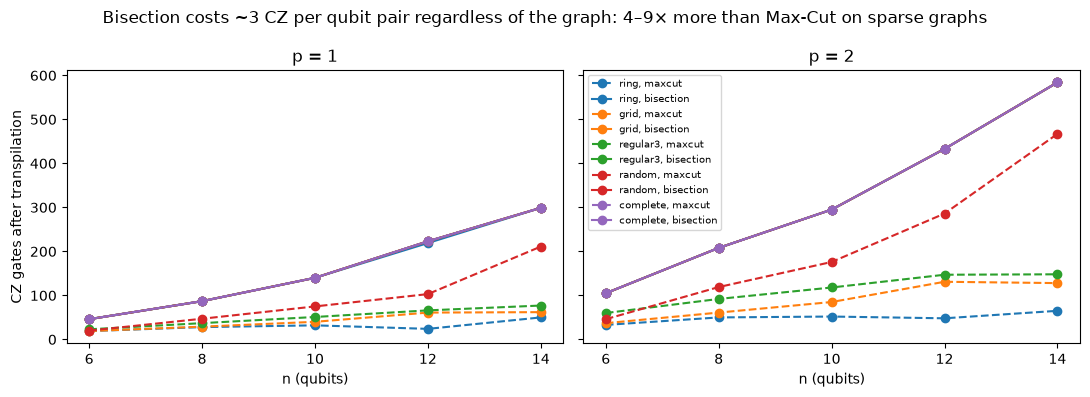

In [ ]:
transpilation = pd.read_csv("../results/transpilation_ibm_boston.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, p in zip(axes, [1, 2]):
    part = transpilation[transpilation["p"] == p]
    for color, graph_type in zip(["C0", "C1", "C2", "C3", "C4"],
                                 ["ring", "grid", "regular3", "random", "complete"]):
        for problem, style in [("maxcut", "--"), ("bisection", "-")]:
            g = part[(part["graph_type"] == graph_type) & (part["problem"] == problem)].sort_values("n")
            ax.plot(g["n"], g["cz_count"], style, color=color, marker="o",
                    label=graph_type + ", " + problem)

    ax.set_title("p = " + str(p))
    ax.set_xlabel("n (qubits)")
    ax.set_xticks([6, 8, 10, 12, 14])

axes[0].set_ylabel("CZ gates after transpilation")
axes[1].legend(fontsize=7)
fig.suptitle("Bisection costs ~3 CZ per qubit pair regardless of the graph: 4–9× more than Max-Cut on sparse graphs")

plt.tight_layout()
plt.savefig("../figures/S_cz_vs_n_ibm_boston.png", dpi=150)
plt.show()

**Interpretation:** Max-Cut grows with the number of edges; bisection grows with the number of qubit **pairs**,
about 3 CZ per pair whatever the graph, because the penalty couples every pair

On sparse graphs this is 4–9x more CZ gates

### Why the order of the Hamiltonian terms matters

In [10]:
for name in ["ring_10", "grid_10", "complete_10"]:
    graph = json_to_graph(find_instance(instances, name))
    H = bisection_hamiltonian(graph, generate_penalty_A(graph))
    row = [r for r in rows_warm if r["name"] == name and r["problem"] == "bisection" and r["p"] == 1][0]

    for label, hamiltonian in [("original order", H), ("sorted order", H.sort())]:
        c = build_qaoa(hamiltonian, 1).assign_parameters(row["params"])
        c.measure_all()
        t, _ = transpile_best(c, backend)
        print(name, label, "| cz:", t.count_ops().get("cz", 0))

ring_10 original order | cz: 166
ring_10 sorted order | cz: 140
grid_10 original order | cz: 194
grid_10 sorted order | cz: 140
complete_10 original order | cz: 140
complete_10 sorted order | cz: 140


The same Hamiltonian with its terms sorted needs fewer CZ gates (ring_10: 166 --> 140, grid_10: 194 --> 140): the order changes
how the transpiler routes the gates

This is why `transpile_qaoa_best` tries both orders

## 4. A first look at noise: Aer noise model
`AerSimulator.from_backend` builds a noise model from the backend calibration (gate and readout errors).
Here it is tested on 12 circuits; the full noisy simulation of all 38 QPU circuits is in `07b_noisy_simulation`.

In [ ]:
noisy_simulator = AerSimulator.from_backend(backend)
print(noisy_simulator)

AerSimulator('aer_simulator_from(ibm_pittsburgh)'
             noise_model=<NoiseModel on ['measure_reset_2', 'reset_2', 'id', 'measure_2', 'x', 'cz', 'measure_reset', 'sx', 'reset', 'xslow', 'measure']>)


In [ ]:
def problem_setup(name, problem):
    """Graph, Hamiltonian, optimum and optimal bitstrings for one instance and problem."""
    graph = json_to_graph(find_instance(instances, name))
    if problem == "maxcut":
        H = max_cut_hamiltonian(graph)
        optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))
        optimum, optimal_bitstrings = bisection_bruteforce(graph)
    return graph, H, optimum, optimal_bitstrings

def find_row(name, problem, p):
    """The row of rows_warm with the optimized angles (and ideal metrics) for one circuit."""
    return [r for r in rows_warm if r["name"] == name and r["problem"] == problem and r["p"] == p][0]

In [13]:
name, problem, p = "ring_6", "maxcut", 1

graph, H, optimum, optimal_bitstrings = problem_setup(name, problem)
row = find_row(name, problem, p)

transpiled, seed, order = transpile_qaoa_best(H, p, row["params"], backend)

job = noisy_simulator.run(transpiled, shots=4000, seed_simulator=42)
counts = job.result().get_counts()

top = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:5]
print("most frequent bitstrings:", top)

probabilities = counts_to_probabilities(counts, graph.number_of_nodes())
noisy = qaoa_metrics(graph, problem, probabilities, optimal_bitstrings)

print("ideal:", {k: round(row[k], 3) for k in ["valid_fraction", "mean_cut", "p_optimal"]})
print("noisy:", {k: round(noisy[k], 3) for k in ["valid_fraction", "mean_cut", "p_optimal"]})

most frequent bitstrings: [('010101', 553), ('101010', 518), ('001011', 149), ('101100', 147), ('100101', 142)]
ideal: {'valid_fraction': 1.0, 'mean_cut': 4.5, 'p_optimal': 0.285}
noisy: {'valid_fraction': 1.0, 'mean_cut': 4.44, 'p_optimal': 0.268}


**Interpretation:** On ring_6 the noise costs little: mean cut 4.50 --> 4.44, P(optimum) 0.285 --> 0.268

The two most frequent bitstrings, 010101 and 101010, are the two optimal cuts of the ring

In [ ]:
raise RuntimeError("DONE 26 Oct (Stage 5) — writes results/transpilation_ibm_boston.csv; do not re-run")

selected = ["ring_6", "grid_10", "regular3_14"]
noisy_rows = []

for name in selected:
    for problem in ["maxcut", "bisection"]:
        graph, H, optimum, optimal_bitstrings = problem_setup(name, problem)

        for p in [1, 2]:
            row = find_row(name, problem, p)
            transpiled, seed, order = transpile_qaoa_best(H, p, row["params"], backend)

            counts = noisy_simulator.run(transpiled, shots=4000, seed_simulator=42).result().get_counts()
            probabilities = counts_to_probabilities(counts, graph.number_of_nodes())
            noisy = qaoa_metrics(graph, problem, probabilities, optimal_bitstrings)

            noisy_rows.append({
                "name": name,
                "graph_type": row["graph_type"],
                "n": row["n"],
                "problem": problem,
                "p": p,
                "cz_count": transpiled.count_ops().get("cz", 0),
                "esp": estimated_success(transpiled, backend),
                "optimum": optimum,
                "ideal_valid_fraction": row["valid_fraction"],
                "noisy_valid_fraction": noisy["valid_fraction"],
                "ideal_mean_cut": row["mean_cut"],
                "noisy_mean_cut": noisy["mean_cut"],
                "ideal_p_optimal": row["p_optimal"],
                "noisy_p_optimal": noisy["p_optimal"],
            })
            print(name, problem, "p =", p, "done")

noisy_results = pd.DataFrame(noisy_rows)
noisy_results.to_csv("../results/stage5_noisy_ibm_pittsburgh.csv", index=False)
noisy_results

## 5. The QPU experiment matrix
9 instances (ring, regular3, random x n = 6, 10, 14), both problems, p = 1 and 2: 36 circuits, plus 2 stress tests

In [ ]:
qpu_names = [graph_type + "_" + str(n)
             for graph_type in ["ring", "regular3", "random"]
             for n in [6, 10, 14]]

transpilation = pd.read_csv("../results/transpilation_ibm_boston.csv")
ideal = pd.read_csv("../results/sim_ideal_warm.csv")
reference = pd.read_csv("../data/reference.csv")[["name", "problem", "random_mean"]]
ideal = ideal.merge(reference, on=["name", "problem"])
ideal["score"] = score(ideal["mean_cut"], ideal["optimum"], ideal["random_mean"])
ideal = ideal[["name", "problem", "p", "score"]]

qpu_list = transpilation[transpilation["name"].isin(qpu_names)]
qpu_list = qpu_list.merge(ideal, on=["name", "problem", "p"])
qpu_list = qpu_list[["name", "graph_type", "n", "problem", "p",
                     "cz_count", "esp", "score", "seed", "order"]]
qpu_list = qpu_list.sort_values(["n", "name", "problem", "p"]).reset_index(drop=True)

print(len(qpu_list), "circuits")
qpu_list

### Stress tests: circuits expected to fail
Bisection at p = 3 on two 14-qubit graphs: ~900 CZ gates and ESP ~= 0.31. They test whether the QPU result drops to random level, as predicted.

In [ ]:
extra = []
for name in ["regular3_14", "random_14"]:
    graph, H, optimum, optimal_bitstrings = problem_setup(name, "bisection")
    row = find_row(name, "bisection", 3)
    transpiled, seed, order = transpile_qaoa_best(H, 3, row["params"], backend)
    extra.append({
        "name": name, "graph_type": row["graph_type"], "n": row["n"],
        "problem": "bisection", "p": 3,
        "cz_count": transpiled.count_ops().get("cz", 0),
        "esp": estimated_success(transpiled, backend),
        "score": ideal[(ideal["name"] == name) & (ideal["problem"] == "bisection")
                       & (ideal["p"] == 3)]["score"].iloc[0],
        "seed": seed, "order": order,
    })
    print(name, "p = 3 done")

qpu_list = pd.concat([qpu_list, pd.DataFrame(extra)], ignore_index=True)
qpu_list.tail(3)

regular3_14 p = 3 done
random_14 p = 3 done


,name,graph_type,n,problem,p,cz_count,esp,score,seed,order
35,ring_14,ring,14,maxcut,2,65,0.797429,0.666667,4,original
36,regular3_14,regular3,14,bisection,3,906,0.310190,0.020138,4,sorted
37,random_14,random,14,bisection,3,906,0.309742,-0.030575,4,sorted


### Predictions before running
Each circuit is labelled from its ESP and ideal score: **fail** (ESP < 0.35 or score < 0.15), **works** (ESP > 0.8 and score > 0.4), otherwise **weak**.
These predictions are checked against the QPU results in `07_analysis` (29 of 38 correct).

In [ ]:
def predict(row):
    if row["esp"] < 0.35 or row["score"] < 0.15:
        return "fail"
    if row["esp"] > 0.8 and row["score"] > 0.4:
        return "works"
    return "weak"

qpu_list["prediction"] = qpu_list.apply(predict, axis=1)
qpu_list["prediction"].value_counts()

prediction
works    18
fail     11
weak      9
Name: count, dtype: int64

In [ ]:
# 3 circuits (n = 6, 10, 14) repeated on 28 Oct to measure day-to-day variability
repeat = [("ring_6", "maxcut", 1), ("regular3_10", "bisection", 1), ("random_14", "maxcut", 1)]
qpu_list["repeat"] = [(r["name"], r["problem"], r["p"]) in repeat for _, r in qpu_list.iterrows()]

In [ ]:
raise RuntimeError("DONE 26 Oct (Stage 5) — writes results/transpilation_ibm_boston.csv; do not re-run")
qpu_list.to_csv("../data/qpu/circuit_list_2026-10-26.csv", index=False)